# Sanity checks of model v2

Step V3 of the [roadmap](../ROADMAP.md), phase 2. Model v2 uses the public SMARD data (`data/README.md`) and only what is known at 12:00 on D-1: the prices of D-1, the day-ahead forecasts of the transmission system operators, measured values shifted by 12 hours and the calendar (`configs/lstm_v2.toml`). Before any feature selection or training, these checks make sure that the new data and the new information set are aligned correctly. Errors here would not crash; they would only make the results too good or too bad.

The checks use the training and validation period only (October 2018 to March 2025); the test period stays untouched.

The checks ran with the starting config of step V2 (13 history features, 8 inputs of day D: the forecasts, the calendar and the measured residual load shifted by 12 hours); `configs/lstm_v2.toml` has since been reduced to the base of the feature selection (V4). The checks of the data and the information set do not depend on that.

In [1]:
import contextlib
import copy
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

from spotforecast.config import PROJECT_ROOT, load_config, load_data_config
from spotforecast.data.dataset import load_datasets, load_preprocessed_data, split_history_future_batch_transform
from spotforecast.data.features import get_input_feature_names
from spotforecast.data.smard import MEASURED, NEIGHBOUR_PRICES
from spotforecast.evaluate import compute_metrics
from spotforecast.models.baselines import fit_ridge, ridge_features, stack_windows
from spotforecast.models.lstm import build_model
from spotforecast.predict import COLORS, CONTEXT_COLOR, MUTED_COLOR, TEXT_COLOR, style_axes

plt.rcParams.update({"figure.facecolor": "white", "figure.dpi": 110})
config = load_config("lstm_v2")
data_config = load_data_config(config)
with contextlib.redirect_stdout(io.StringIO()):  # the preprocessing log is long
    train_ds, valid_ds, _ = load_datasets(config, data_config)  # the test split is not used
splits = {"train": train_ds, "validation": valid_ds}
feature_names = get_input_feature_names(config["features"])
raw = pd.read_parquet(PROJECT_ROOT / data_config["path"]).set_index("Date")
development = raw.loc[:"2025-03-31"]  # training and validation period

print(f"{len(train_ds)} training days, {len(valid_ds)} validation days")
print(f"history features ({len(feature_names)}): {feature_names}")
print(f"inputs of day D ({len(config['targets']) - 1}): {config['targets'][1:]}")

1989 training days, 363 validation days
history features (13): ['Spot', 'forecast load', 'forecast residual load', 'forecast onshore wind', 'forecast offshore wind', 'forecast solar', 'saturday', 'sunday', 'holiday', 'residual load_lag12', 'Spot_roll_168', 'hour_sin', 'hour_cos']
inputs of day D (8): ['forecast load', 'forecast residual load', 'forecast onshore wind', 'forecast offshore wind', 'forecast solar', 'saturday', 'sunday', 'holiday']


## 1. Alignment of history, targets and time

**Why:** the windows are cut from one long table by index arithmetic. An off-by-one shifts the targets against the history; with the new data source and the longer period (clock changes, the excluded day) the day boundaries have to be checked again.

**Passes if:** the spot price in the features equals the target; every history ends at 23:00 and every target day runs from 00:00 to 23:00; the only days without a forecast are the clock changes and, in training, the excluded 26 June 2024.

In [2]:
for name, ds in splits.items():
    X, Y = stack_windows(ds)
    diff_rows = (ds.features[:, 0] - ds.target[:, 0]).abs().max().item()
    starts = ds.forecast_starts()
    history_end = ds.dates[ds.usable_idxs + ds.window - 1]
    target_end = ds.dates[ds.usable_idxs + ds.window + ds.horizon - 1]
    all_days = pd.date_range(starts[0].date(), starts[-1].date(), freq="D")
    skipped = all_days.difference(pd.DatetimeIndex(starts.date))
    print(f"{name}: spot in features vs target, largest difference {diff_rows:.1e}; history ends at "
          f"{set(history_end.hour)}:00, targets from {set(starts.hour)}:00 to {set(target_end.hour)}:00 of the same day: "
          f"{(target_end.date == starts.date).all()}; finite: {np.isfinite(X).all() and np.isfinite(Y).all()}")
    print(f"    days without a forecast: {[d.date().isoformat() for d in skipped]}")
    assert diff_rows < 1e-5 and set(history_end.hour) == {23} and set(starts.hour) == {0}

train: spot in features vs target, largest difference 0.0e+00; history ends at {23}:00, targets from {0}:00 to {23}:00 of the same day: True; finite: True
    days without a forecast: ['2018-10-28', '2019-03-31', '2019-10-27', '2020-03-29', '2020-10-25', '2021-03-28', '2021-10-31', '2022-03-27', '2022-10-30', '2023-03-26', '2023-10-29']
validation: spot in features vs target, largest difference 0.0e+00; history ends at {23}:00, targets from {0}:00 to {23}:00 of the same day: True; finite: True
    days without a forecast: ['2024-10-27', '2025-03-30']


**Result: passed.** The spot price in the features equals the target, every history ends at 23:00 and every target day runs from 00:00 to 23:00. The only days without a forecast are the clock changes (11 in training, 2 in validation).

## 2. Are the forecasts aligned with what they forecast?

**Why:** the day-ahead forecasts are the most important inputs of v2. If SMARD stored them shifted by an hour, e.g. in another time zone, the model would get the forecast of the wrong hour. A forecast must correlate best with the measurement of the same hour.

**Passes if:** the correlation of every forecast with its measurement is highest at a shift of 0 hours, and the daily solar profiles of forecast and measurement peak at the same hour.

,shift -3 h,shift -2 h,shift -1 h,shift +0 h,shift +1 h,shift +2 h,shift +3 h
forecast load,0.7398,0.8527,0.9340,0.9660,0.9380,0.8593,0.7473
forecast onshore wind,0.9475,0.9663,0.9802,0.9869,0.9854,0.9763,0.9617
forecast offshore wind,0.8769,0.9028,0.9220,0.9320,0.9307,0.9193,0.8997
forecast solar,0.6640,0.8355,0.9534,0.9952,0.9519,0.8328,0.6606


best shift: {'forecast load': 0, 'forecast onshore wind': 0, 'forecast offshore wind': 0, 'forecast solar': 0}


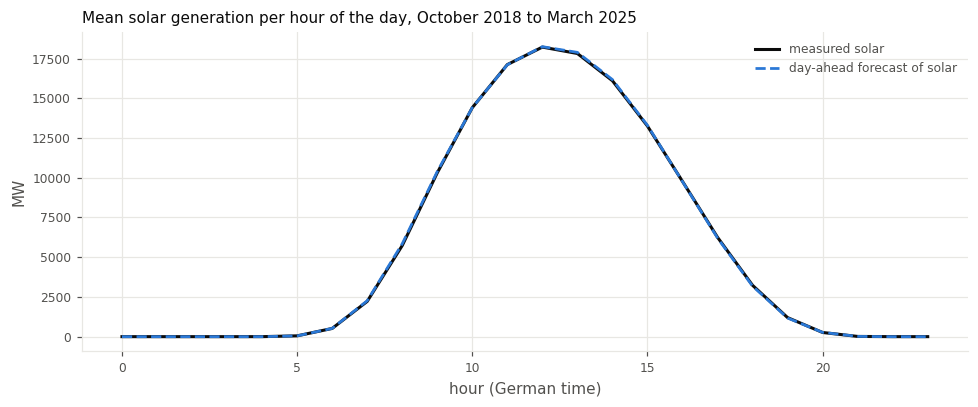

In [3]:
pairs = {"forecast load": "conso", "forecast onshore wind": "onshore wind", "forecast offshore wind": "offshore wind",
         "forecast solar": "solar"}
lags = range(-3, 4)
correlation = pd.DataFrame({forecast: {lag: development[forecast].corr(development[measured].shift(lag)) for lag in lags}
                            for forecast, measured in pairs.items()}).T
correlation.columns = [f"shift {lag:+d} h" for lag in lags]
display(correlation.round(4))
print("best shift:", {forecast: int(correlation.loc[forecast].values.argmax()) - 3 for forecast in pairs})

hour = development.index.hour
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(development["solar"].groupby(hour).mean(), color=TEXT_COLOR, linewidth=2, label="measured solar")
ax.plot(development["forecast solar"].groupby(hour).mean(), color=COLORS["final model"], linewidth=1.8, linestyle="--",
        label="day-ahead forecast of solar")
style_axes(ax, "Mean solar generation per hour of the day, October 2018 to March 2025")
ax.set_xlabel("hour (German time)")
ax.set_ylabel("MW")
ax.legend(frameon=False, fontsize=8, labelcolor=MUTED_COLOR)
plt.tight_layout()
plt.show()

**Result: passed.** Every forecast correlates best with the measurement of the same hour (shift 0; load 0.966, onshore wind 0.987, offshore wind 0.932, solar 0.995), and the solar profiles of forecast and measurement peak at the same hour. SMARD stores forecasts and measurements on the same time axis.

## 3. The 12-hour shift of measured values

**Why:** at 12:00 on D-1 the measured values of the afternoon of D-1 are not known yet. `residual load_lag12` must therefore hold, at every hour, the measured residual load of 12 hours earlier; at 23:00 on D-1, the last hour of the history, that is the value of 11:00.

**Passes if:** the shifted column equals the measured one 12 hours earlier, and the v2 config uses no measured value and no price of the same auction as an input of day D.

In [4]:
preprocessing = dict(data_config["preprocessing"])
preprocessing.pop("valid_cutoff_datetime")
preprocessing.pop("test_cutoff_datetime")
with contextlib.redirect_stdout(io.StringIO()):
    frame = load_preprocessed_data(PROJECT_ROOT / data_config["path"], ["residual load_lag12"], preprocessing)
shifted = frame["residual load"].shift(12)
print(f"residual load_lag12 vs residual load 12 hours earlier, largest difference: "
      f"{(frame['residual load_lag12'] - shifted).iloc[12:].abs().max():.3f} MW")
at_23 = frame[frame["Date"].dt.hour == 23].iloc[100]
at_11 = frame[frame["Date"] == at_23["Date"] - pd.Timedelta(hours=12)].iloc[0]
print(f"example: at {at_23['Date']:%Y-%m-%d %H:%M} the shifted column holds {at_23['residual load_lag12']:.0f} MW, "
      f"the residual load of {at_11['Date']:%H:%M} was {at_11['residual load']:.0f} MW")

measured = set(MEASURED) | {"residual load"}
print("measured values in the history without a shift:", sorted(measured & set(config["features"])) or "none")
print("measured values or neighbour prices as inputs of day D:",
      sorted((measured | set(NEIGHBOUR_PRICES)) & set(config["targets"][1:])) or "none")

residual load_lag12 vs residual load 12 hours earlier, largest difference: 0.000 MW
example: at 2019-01-09 23:00 the shifted column holds 40017 MW, the residual load of 11:00 was 40017 MW
measured values in the history without a shift: none
measured values or neighbour prices as inputs of day D: none


**Result: passed.** `residual load_lag12` equals the measured residual load 12 hours earlier at every hour; at 23:00 on D-1 it holds the value of 11:00. The v2 config uses no unshifted measured value and no price of the same auction as an input of day D.

## 4. Quality of the forecasts over the years

**Why:** the model learns how the price reacts to the forecasts. If the forecasts became much better or worse over the years (or changed their definition), the training years would teach the model something that no longer holds in the validation year.

**Passes if:** the forecast errors change only gradually, e.g. growing with the installed solar capacity, without breaks.

In [5]:
years = development.index.year
errors = pd.DataFrame({forecast: (development[forecast] - development[measured]).abs().groupby(years).mean()
                       for forecast, measured in pairs.items()})
errors["forecast residual load"] = (development["forecast residual load"]
                                    - (development["conso"] - development["onshore wind"] - development["offshore wind"]
                                       - development["solar"])).abs().groupby(years).mean()
print("mean absolute error of the day-ahead forecasts in MW (2018: October to December, 2025: January to March)")
display(errors.round(0))

mean absolute error of the day-ahead forecasts in MW (2018: October to December, 2025: January to March)


,forecast load,forecast onshore wind,forecast offshore wind,forecast solar,forecast residual load
Date,,,,,
2018,2116.0,1158.0,470.0,245.0,2486.0
2019,2401.0,1072.0,416.0,333.0,2676.0
2020,1821.0,1068.0,455.0,346.0,2259.0
2021,2267.0,994.0,428.0,375.0,2558.0
2022,2196.0,1067.0,457.0,427.0,2619.0
2023,1943.0,1186.0,566.0,438.0,2536.0
2024,1963.0,1126.0,569.0,569.0,2595.0
2025,2050.0,1257.0,544.0,575.0,2679.0


**Result: passed.** The forecast errors change only gradually: the load about 1.8 to 2.4 GW, onshore wind 1.0 to 1.3 GW, the residual load 2.3 to 2.7 GW per year; the solar error grows with the installed capacity (245 MW at the end of 2018, 575 MW in 2025). No breaks in the definitions.

## 5. Model start and overfitting a single batch

**Why:** v2 has other inputs than v1 (13 history features, 8 inputs of day D). With `zero_init_output` the untrained model must forecast exactly the last known price (persistence), and a working network must be able to memorize 64 days.

**Passes if:** the untrained model equals persistence, `pred.shape == y.shape`, and the loss falls below about 0.01 within 500 steps.

In [6]:
X_train, Y_train = stack_windows(train_ds)
overfit_config = copy.deepcopy(config)
overfit_config["net_params"]["dropout_p"] = 0.0
model = build_model(overfit_config, X_train.shape[-1], Y_train.shape[-1] - 1, rng=torch.Generator().manual_seed(1))
x_batch, y_batch = split_history_future_batch_transform(torch.from_numpy(X_train[:64]), torch.from_numpy(Y_train[:64]),
                                                        torch.device("cpu"), train=False)
model.eval()
with torch.no_grad():
    pred = model(x_batch)
persistence = x_batch[0][:, -1:, 0].expand_as(y_batch)
print(f"shapes: pred {tuple(pred.shape)}, y {tuple(y_batch.shape)}; untrained model vs persistence, largest difference "
      f"{(pred - persistence).abs().max().item():.1e}")
assert pred.shape == y_batch.shape

torch.manual_seed(1)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)
criterion = torch.nn.MSELoss()
model.train()
for step in range(1, 501):
    optimizer.zero_grad()
    loss = criterion(model(x_batch), y_batch)
    loss.backward()
    optimizer.step()
    if step % 100 == 0:
        print(f"step {step}: loss {loss.item():.4f}")

shapes: pred (64, 24), y (64, 24); untrained model vs persistence, largest difference 0.0e+00
step 100: loss 0.0003
step 200: loss 0.0000
step 300: loss 0.0000
step 400: loss 0.0000
step 500: loss 0.0000


**Result: passed.** The untrained model forecasts exactly the last known price (difference 0), the shapes match, and the model memorizes the batch (loss 0.0003 after 100 steps, below 0.0001 after 200).

## 6. The decoupling day in the validation year

**Why:** 26 June 2024, the day of the technical decoupling with prices up to 2326 EUR/MWh, is no training target, but it lies in the validation year of v2 and is evaluated there. No model can forecast it. How much does it change the validation numbers that all decisions of v2 are based on?

**Passes if:** this is only a question to decide: the numbers below show its effect on Ridge.

In [7]:
X_val, Y_val = stack_windows(valid_ds)
pred = fit_ridge(train_ds).predict(ridge_features(X_val, Y_val))
days = valid_ds.forecast_starts()
keep = days.strftime("%Y-%m-%d") != "2024-06-26"
scale = valid_ds.target_scaler.scale_[0]
abs_err = np.abs(pred - Y_val[:, :, 0]) * scale
print(f"Ridge on the validation year: MAE {abs_err.mean():.2f} with 26 June 2024, {abs_err[keep].mean():.2f} without; "
      f"RMSE {np.sqrt((abs_err ** 2).mean()):.1f} with, {np.sqrt((abs_err[keep] ** 2).mean()):.1f} without")
print(f"MAE on 26 June 2024 alone: {abs_err[~keep].mean():.0f} EUR/MWh")

Ridge on the validation year: MAE 16.25 with 26 June 2024, 16.24 without; RMSE 30.4 with, 30.4 without
MAE on 26 June 2024 alone: 20 EUR/MWh


**Result: no problem, but a finding.** In the SMARD data 26 June 2024 has normal prices (mean 103 EUR/MWh, almost the same as Austria); the decoupled prices up to 2326 EUR/MWh are only in the course data of phase 1. Most likely there were two prices on that day: that of the decoupled EPEX SPOT auction (course data) and that of the European market coupling (SMARD). The day does not change the validation numbers (Ridge MAE 16.25 with, 16.24 without it), and `exclude_days` is not needed for v2.

## Summary

| Check | Result |
|---|---|
| 1. Alignment of history, targets and time | passed |
| 2. Forecasts aligned with the measurements | passed, best correlation at a shift of 0 hours |
| 3. 12-hour shift and information set | passed |
| 4. Forecast quality over the years | passed, gradual changes only |
| 5. Model start and overfit test | passed |
| 6. Decoupling day in the validation year | no problem: SMARD has normal prices on 26 June 2024 |

No check found an error in the SMARD data or in the information set of v2. The next step is the feature selection (V4).